# HRP pilot: Can Qwen3 faithfully explain readmission risk predictions?

**Entirely fictional demonstration — NO MIMIC data.** This notebook generates artificial patients and artificial readmission labels, fits a logistic-regression model, computes **actual model-based SHAP attributions**, and compares two explanations from **Qwen3 8B running locally through Ollama**.

**Experimental conditions:**
- **Baseline:** the LLM sees fictional patient features and the fitted model's risk estimate, but no feature attribution.
- **SHAP-grounded:** the same LLM additionally receives the model's SHAP contributions in **log-odds units**.

The model, labels, and resulting risk estimates are artificial and **must not** be interpreted as validated clinical predictions. The purpose is to test whether an LLM describes *what a model used*, not whether the model is medically correct.

**Privacy:** No real patient records, MIMIC data, trained MIMIC model, or MIMIC-derived outputs are used. Calls are made to `127.0.0.1`, which should point to your local Ollama process. Do not change this URL to a remote endpoint with restricted data.

## 0. Setup

Use `uv sync` in the VS Code terminal to create `.venv` from `pyproject.toml`; select `.venv/bin/python` as the notebook kernel. Start Ollama and ensure `qwen3:8b` is installed. The cells before the LLM calls work **without Ollama**.


In [1]:
import sys
import ipykernel

print("Python:", sys.executable)
print("ipykernel:", ipykernel.__version__)

Python: /Users/sghosh/Documents/Github/AI380H/HRP/.venv/bin/python
ipykernel: 7.4.0


In [2]:
from __future__ import annotations

import json
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import shap

from IPython.display import display, Markdown
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
OLLAMA_URL = "http://127.0.0.1:11434"  # local machine only
MODEL_NAME = "qwen3:8b"
np.random.seed(SEED)
print("Dependencies loaded. SHAP version:", shap.__version__)

/Users/sghosh/Documents/Github/AI380H/HRP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dependencies loaded. SHAP version: 0.54.1


## 1. Generate completely synthetic patient-like data

The numbers are deliberately fabricated and the outcome arises from a known synthetic equation. The features resemble a small EHR table but are **not sampled from or calibrated to MIMIC**. We fit a separate predictive model so there is an actual set of model parameters to explain.

In [3]:
rng = np.random.default_rng(SEED)
n = 2400
synthetic = pd.DataFrame({
    "age_years": rng.integers(20, 91, n),
    "prior_admissions": np.clip(rng.poisson(1.3, n), 0, 8),
    "creatinine_mg_dl": np.clip(rng.normal(1.1, 0.42, n), 0.45, 3.5),
    "hemoglobin_g_dl": np.clip(rng.normal(12.8, 1.8, n), 7, 18),
    "sodium_mmol_l": np.clip(rng.normal(138, 4.5, n), 120, 153),
    "heart_rate_bpm": np.clip(rng.normal(86, 16, n), 45, 145),
})

# Artificial coefficients, not clinically derived associations.
synthetic_logit = (
    -2.0 + 0.032 * (synthetic.age_years - 55)
    + 0.44 * synthetic.prior_admissions
    + 0.80 * (synthetic.creatinine_mg_dl - 1.1)
    - 0.11 * (synthetic.hemoglobin_g_dl - 12.8)
    - 0.035 * (synthetic.sodium_mmol_l - 138)
    + 0.014 * (synthetic.heart_rate_bpm - 86)
)
y = rng.binomial(1, expit(synthetic_logit))
X_train, X_test, y_train, y_test = train_test_split(
    synthetic, y, test_size=0.25, random_state=SEED, stratify=y
)
print(f"Fictional records: {n:,}; artificial outcome prevalence: {y.mean():.1%}")
display(synthetic.head(3))

Fictional records: 2,400; artificial outcome prevalence: 23.9%


,age_years,prior_admissions,creatinine_mg_dl,hemoglobin_g_dl,sodium_mmol_l,heart_rate_bpm
0,26,2,1.170414,10.934766,131.811233,88.950300
1,74,1,1.620452,11.764607,138.281400,83.215971
2,66,0,1.061824,14.244000,136.672724,78.168089


## 2. Fit a genuine predictive model

We use standardized logistic regression, which makes feature attribution easy to inspect. Even on synthetic data, a model is not perfect; its explanations should be evaluated relative to its *learned coefficients*, not our hand-written generating equation.

In [4]:
scaler = StandardScaler()
X_train_z = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_z = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
clf = LogisticRegression(max_iter=2000, random_state=SEED)
clf.fit(X_train_z, y_train)
score = roc_auc_score(y_test, clf.predict_proba(X_test_z)[:, 1])
print(f"Holdout ROC AUC (artificial labels): {score:.3f}")
print("Note: This number says NOTHING about real clinical performance.")

Holdout ROC AUC (artificial labels): 0.719
Note: This number says NOTHING about real clinical performance.


## 3. Compute model SHAP values and check additivity

For a linear logistic model with the training-set reference distribution, SHAP values describe each feature's contribution on the **log-odds (logit) scale**. They are not changes in probability and do not identify causal effects. We verify that `expected_value + sum(SHAP)` equals the fitted model's decision score.

In [5]:
background = X_train_z.sample(n=min(250, len(X_train_z)), random_state=SEED)
explainer = shap.LinearExplainer(clf, background)
# Pick a moderately elevated-risk fictional test example for an informative explanation.
probs = clf.predict_proba(X_test_z)[:, 1]
selected_pos = int(np.argmin(np.abs(probs - 0.55)))
patient_z = X_test_z.iloc[[selected_pos]]
patient = X_test.iloc[selected_pos]
prediction = float(probs[selected_pos])
sv = explainer(patient_z)
shap_values = np.asarray(sv.values).reshape(-1)
base_logodds = float(np.asarray(sv.base_values).reshape(-1)[0])
model_logodds = float(clf.decision_function(patient_z)[0])
assert np.isclose(base_logodds + shap_values.sum(), model_logodds, atol=1e-5)
assert np.isclose(expit(model_logodds), prediction, atol=1e-6)

contributions = pd.DataFrame({
    "feature": X_train.columns,
    "value": patient.to_numpy(),
    "shap_logodds": shap_values,
})
contributions["effect"] = np.where(contributions.shap_logodds > 0, "increases", "decreases")
contributions["abs_contribution"] = contributions.shap_logodds.abs()
contributions = contributions.sort_values("abs_contribution", ascending=False).reset_index(drop=True)
print(f"Selected fictional test case index: {patient.name}")
print(f"Model-predicted artificial readmission probability: {prediction:.1%}")
print(f"Base log-odds: {base_logodds:.3f}; sum SHAP: {shap_values.sum():+.3f}; model log-odds: {model_logodds:+.3f}")
display(contributions)

Background dataset has 250 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=250 when initializing the masker.


Selected fictional test case index: 322
Model-predicted artificial readmission probability: 54.9%
Base log-odds: -1.390; sum SHAP: +1.585; model log-odds: +0.195


,feature,value,shap_logodds,effect,abs_contribution
0,creatinine_mg_dl,1.680578,0.484379,increases,0.484379
1,age_years,63.000000,0.317112,increases,0.317112
2,prior_admissions,2.000000,0.307936,increases,0.307936
3,sodium_mmol_l,132.690462,0.225122,increases,0.225122
4,heart_rate_bpm,96.789409,0.215376,increases,0.215376
5,hemoglobin_g_dl,12.272508,0.035396,increases,0.035396


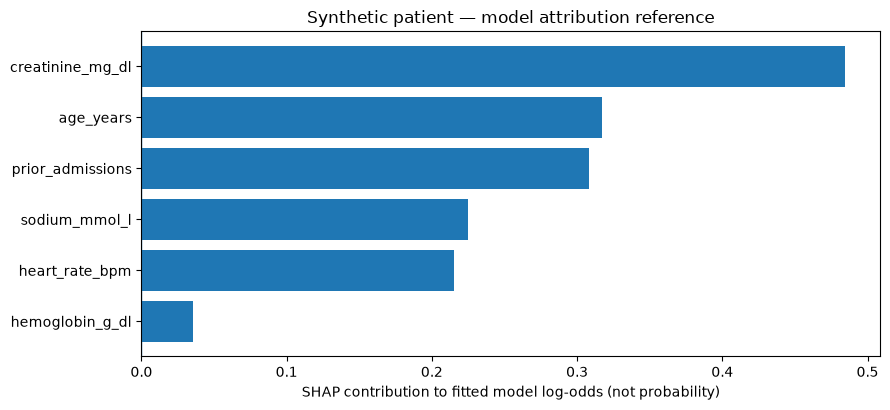

In [6]:
ordered = contributions.sort_values("shap_logodds")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(ordered.feature, ordered.shap_logodds)
ax.axvline(0, linewidth=1)
ax.set_xlabel("SHAP contribution to fitted model log-odds (not probability)")
ax.set_title("Synthetic patient — model attribution reference")
plt.tight_layout()
plt.show()

## 4. Prepare matched prompts

Both prompts use the **same model prediction and feature values**. The grounded prompt alone adds SHAP feature attributions. For easier evaluation, request a small JSON object containing an explanation and a list of claimed influential features. We do not tell the baseline which features are truly important.

In [7]:
feature_lines = "\n".join(f"- {feature}: {value:.2f}" for feature, value in patient.items())
shap_lines = "\n".join(
    f"- {row.feature}: {row.shap_logodds:+.3f} log-odds ({row.effect} predicted risk relative to model baseline)"
    for row in contributions.itertuples()
)
common_instructions = """You explain a statistical prediction model, NOT actual medical risk.
All data are fictional and the model was trained on artificial labels.
Write a plain-English explanation of what the model is using; do not claim causality, medical validity, or treatment guidance.
Avoid inventing model behavior. If attributions are unavailable, acknowledge the uncertainty.
Use only feature names from the supplied list.
Return JSON ONLY with these keys:
  "explanation": a concise paragraph (2-4 sentences),
  "drivers": a list of up to 3 objects, each with "feature" (exact listed name) and
             "direction" (exactly "increases" or "decreases").
The direction refers to contribution to THIS model's predicted risk, not a clinical association.
"""
case_context = f"""Artificial patient-like values:
{feature_lines}

Model-estimated probability for artificial readmission label: {prediction:.1%}.
"""
baseline_prompt = common_instructions + "\n" + case_context + "\nNo model-attribution information is provided."
grounded_prompt = (common_instructions + "\n" + case_context
                   + "\nThe following are SHAP values calculated from this exact fitted model. "
                   + "They are additive on the log-odds scale (NOT percentage-point changes). "
                   + "Prioritize the largest absolute SHAP contributions:\n" + shap_lines)
print("Baseline prompt characters:", len(baseline_prompt))
print("Grounded prompt characters:", len(grounded_prompt))

Baseline prompt characters: 1031
Grounded prompt characters: 1707


## 5. Call the local Qwen3 model using Ollama

This is the **only** section that needs Ollama. The notebook checks `/api/tags` first and will skip inference with a clear message if Ollama is not running or Qwen3 8B is missing. It will never silently send your data to a hosted model. Each prompt is a separate, stateless request with `temperature=0` and thinking disabled.

In [8]:
def check_local_ollama(url=OLLAMA_URL, model=MODEL_NAME):
    if not (url.startswith("http://127.0.0.1:") or url.startswith("http://localhost:")):
        raise ValueError("This pilot only permits loopback Ollama URLs.")
    try:
        response = requests.get(f"{url}/api/tags", timeout=5)
        response.raise_for_status()
        available = {item["name"] for item in response.json().get("models", [])}
        if model not in available:
            print(f"Ollama responded, but {model} is not installed. Available: {sorted(available)}")
            return False
        return True
    except requests.RequestException as err:
        print(f"Local Ollama is not available: {err}")
        print("Open the Ollama app, or run `ollama serve` if the app is not running.")
        return False

def run_local_llm(prompt: str, model=MODEL_NAME):
    payload = {
        "model": model,
        "prompt": prompt,
        "stream": False,
        "think": False,
        "format": "json",
        "keep_alive": "10m",
        "options": {"temperature": 0, "num_predict": 450, "num_ctx": 4096},
    }
    t0 = time.perf_counter()
    response = requests.post(f"{OLLAMA_URL}/api/generate", json=payload, timeout=240)
    response.raise_for_status()
    obj = response.json()
    return obj.get("response", ""), time.perf_counter() - t0

outputs = {}
if check_local_ollama():
    for condition, prompt in [("Baseline", baseline_prompt), ("SHAP-grounded", grounded_prompt)]:
        try:
            raw, seconds = run_local_llm(prompt)
            outputs[condition] = {"raw": raw, "seconds": seconds}
            print(f"{condition}: generated in {seconds:.1f}s")
        except requests.RequestException as exc:
            print(f"{condition}: local request failed: {exc}")
else:
    print("Skipping LLM calls. Earlier model and SHAP cells still completed successfully.")

Baseline: generated in 7.9s
SHAP-grounded: generated in 7.8s


## 6. Inspect explanations and calculate a limited feature-faithfulness score

**Automated metric:** Among a model's declared top 3 drivers, how many match the **top 3 absolute SHAP contributors with the correct sign**? We also count declared features outside the supplied six. This does **not** verify every statement in the prose, and no clinical-expert readability assessment is performed. Review prose manually for invented claims or causal assertions.

In [9]:
def parse_response(raw: str):
    try:
        obj = json.loads(raw)
        if not isinstance(obj, dict):
            raise ValueError("Expected JSON object")
        return obj
    except (json.JSONDecodeError, ValueError):
        match = re.search(r"\{.*\}", raw, flags=re.S)
        if match:
            try:
                return json.loads(match.group())
            except json.JSONDecodeError:
                pass
        return {"explanation": raw, "drivers": []}

reference = {r.feature: r.effect for r in contributions.head(3).itertuples()}
allowed = set(X_train.columns)
records = []
for name, result in outputs.items():
    obj = parse_response(result["raw"])
    driver_list = obj.get("drivers", [])
    if not isinstance(driver_list, list):
        driver_list = []
    drivers = [d for d in driver_list if isinstance(d, dict)][:3]
    matches = sum(d.get("feature") in reference and
                  d.get("direction") == reference.get(d.get("feature")) for d in drivers)
    invalid_features = sum(d.get("feature") not in allowed for d in drivers)
    records.append({"condition": name, "time_s": round(result["seconds"], 1),
                    "correct_top3_feature_and_direction": matches,
                    "declared_drivers": len(drivers),
                    "unsupported_feature_names": invalid_features,
                    "explanation": obj.get("explanation", ""),
                    "drivers": drivers})
    display(Markdown(f"### {name}\n\n{obj.get('explanation', '(No explanation returned)')}"))
    display(pd.DataFrame(drivers))

if records:
    summary = pd.DataFrame(records)
    display(summary[["condition", "time_s", "correct_top3_feature_and_direction", "declared_drivers", "unsupported_feature_names"]])
    print("Reference top-3 SHAP drivers:", reference)
else:
    print("No model responses available. Start Ollama and rerun Sections 5–6.")

### Baseline

This model predicts the likelihood of a readmission based on various patient characteristics. It uses a combination of features to estimate the probability, without implying any direct medical causation or treatment guidance.

,feature,direction
0,age_years,increases
1,prior_admissions,increases
2,creatinine_mg_dl,increases


### SHAP-grounded

This model predicts the likelihood of a fictional readmission label based on several patient features. It uses a combination of clinical and demographic factors to estimate risk, with higher values in certain features contributing to an increased predicted risk.

,feature,direction
0,creatinine_mg_dl,increases
1,age_years,increases
2,prior_admissions,increases


,condition,time_s,correct_top3_feature_and_direction,declared_drivers,unsupported_feature_names
0,Baseline,7.9,3,3,0
1,SHAP-grounded,7.8,3,3,0


Reference top-3 SHAP drivers: {'creatinine_mg_dl': 'increases', 'age_years': 'increases', 'prior_admissions': 'increases'}


## 7. Manual review and interpretation

Use these questions for a qualitative comparison:

1. Does the explanation **correctly distinguish model contribution from medical causation**?
2. Does it discuss the **largest actual SHAP drivers**, not simply common medical stereotypes?
3. Are feature directions correct? Is there a false claim that SHAP values represent **changes in probability**?
4. Are important uncertainties visible (toy data, model not validated, small sample)?
5. Is the explanation understandable to a nontechnical reader?

**Pilot limitations:** one fictional case; one local model; no clinical raters; crude top-3 structured metric. The next experiment should use dozens of fictional cases and report distributions, parse failures, manual error codes, and paired comparisons. Re-running with multiple prompt variants can test robustness.

**Do not upload real MIMIC records or MIMIC-derived patient-level artifacts to public repositories or hosted inference services.** The toy data here are independent and self-contained.